# 1회차 따라 치기 실습 — 템플릿 매칭을 한 단계씩 만들기
## 상세 설명 · 정규화 상관계수 · 점수 지도 · 변화에 대한 실험

**원본:** `s01_my_template_matching.py`의 STEP 1~7을 노트북 환경에 맞추어 구성했습니다. 창을 띄우는 `cv2.imshow()`와 `waitKey()`는 셀 안에 그림을 표시하는 Matplotlib으로 바꾸었습니다.

템플릿 매칭은 작은 기준 그림을 큰 영상의 모든 가능한 위치에 대어 보고 가장 비슷한 자리를 찾습니다. 여기서는 우주비행사 사진에서 얼굴 부분을 잘라 템플릿으로 사용합니다.

| 용어 | 의미 |
|---|---|
| 검색 영상 $I$ | 찾을 대상이 들어 있는 큰 영상 |
| 템플릿 $T$ | 찾으려는 작은 기준 영상 |
| 점수 지도 $R$ | 템플릿을 각 위치에 놓았을 때의 유사도 |
| 최고점 위치 | 템플릿 왼쪽 위 모서리를 놓을 위치 $(x,y)$ |

**학습 목표:** 영상 배열의 좌표를 이해하고, 매칭 수식과 점수 지도·최고점·검출 상자를 연결합니다. 밝기·크기·좌우 반전 변화에 대한 성능을 비교하고, 자기 자신과의 매칭 결과를 과대 해석하지 않습니다.

이 실습에서는 **템플릿을 사람이 직접 지정**합니다. 정답 데이터로 가중치를 갱신하는 학습 단계는 없습니다. 이전의 임계값 학습 실습과 구분하세요.


## 0. 실행 준비

Python 3의 Jupyter Notebook/JupyterLab 또는 VS Code에서 커널을 선택하고 위에서부터 실행하세요. `numpy`, `opencv-python`, `matplotlib`, `scikit-image`가 필요합니다. 설치가 필요하면 아래 셀의 주석을 해제합니다. `skimage`의 설치 패키지 이름은 `scikit-image`입니다.

기본 예제는 `skimage.data.astronaut()`를 사용합니다. 원본의 `face.jpg` 우선 읽기 동작도 선택할 수 있도록 남겨 두었습니다. **다른 사진을 사용하면 얼굴 좌표도 직접 바꿔야 합니다.** 그림 제목과 축은 글꼴 호환성을 위해 영어로 표시합니다. 배포본에는 실행 결과가 저장되어 있습니다.


In [3]:
# 필요한 경우 실행한 뒤 커널을 재시작하세요.
# %pip install numpy opencv-python matplotlib scikit-image


In [1]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('OpenCV:', cv2.__version__, '| NumPy:', np.__version__)


OpenCV: 4.14.0 | NumPy: 2.4.6


## STEP 1. 사진 읽고 흑백으로 바꾸기

OpenCV는 컬러 영상을 일반적으로 **BGR** 순서로 다룹니다. 반면 `data.astronaut()`와 Matplotlib은 **RGB** 순서를 사용합니다. 원본 코드와 같게 작업용 컬러 영상 `img`는 BGR로 통일하고, 그림을 표시할 때 RGB로 되돌립니다.

`gray.shape`는 `(높이, 너비)`입니다. 흑백 영상은 픽셀마다 밝기 한 개를 저장하므로 2차원 배열입니다. 흑백 변환은 색 채널의 가중합이며, 이후 매칭은 이 밝기 영상만 비교합니다. 따라서 밝기는 비슷하지만 색이 다른 물체를 구분하는 정보는 사라집니다.

기본 예제 얼굴 위치 `(177, 66, 95, 95)`는 astronaut 사진에 맞는 값입니다. `USE_LOCAL_FACE=True`로 바꾸면 현재 작업 폴더의 `face.jpg`를 읽고, 읽지 못하면 예제 사진으로 대체합니다. 로컬 사진 사용 시 다음 셀의 좌표를 꼭 확인하세요.


STEP1: (512, 512) uint8 | source: skimage.data.kidney


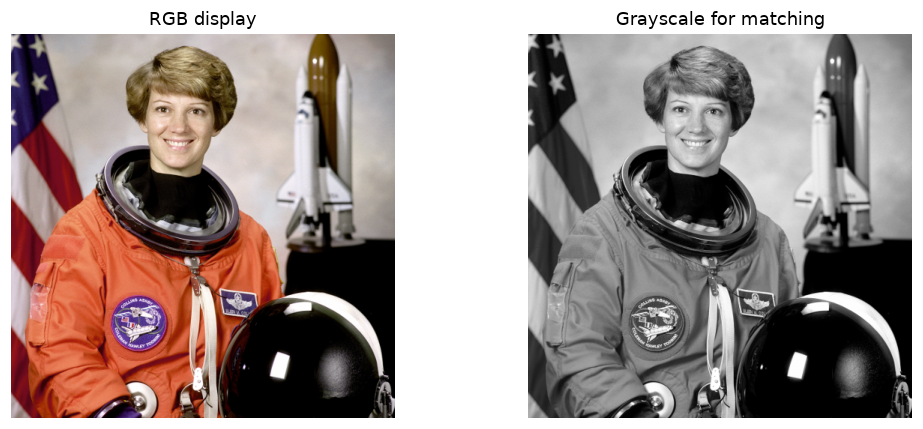

In [2]:
USE_LOCAL_FACE = False
img = cv2.imread(str(Path('face.jpg'))) if USE_LOCAL_FACE else None
if img is None:
    img = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR)
    source_name = 'skimage.data.kidney'
else:
    source_name = 'face.jpg (set your own ROI)'
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print('STEP1:', gray.shape, gray.dtype, '| source:', source_name)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title('RGB display')
axes[1].imshow(gray, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Grayscale for matching')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()


## STEP 2. 템플릿 잘라내기 — $(x,y)$와 `[y,x]`

영상 좌표는 오른쪽으로 $x$, 아래쪽으로 $y$가 증가합니다. 반면 NumPy 배열은 `[행, 열]`, 즉 `[y, x]` 순서로 읽습니다.

$$T=I[y:y+h,\;x:x+w]$$

슬라이스의 끝 인덱스는 포함하지 않습니다. 따라서 열 `177:272`는 177~271의 95개 픽셀입니다. 영상 전체 크기를 $(H,W)$, 템플릿 크기를 $(h,w)$로 표기하겠습니다.

템플릿은 **이번 사진 속 특정 얼굴의 실제 픽셀 패턴**입니다. 모든 사람의 얼굴을 대표하는 일반적인 얼굴 모델이 아닙니다. 또한 밝기가 일정한 템플릿은 분산이 0이 되어 다음 정규화 상관계수의 분모가 0이 됩니다. 그런 템플릿의 점수는 해석할 수 없으므로 미리 검사합니다.


STEP2: (95, 95) | mean: 155.58 | std: 52.68


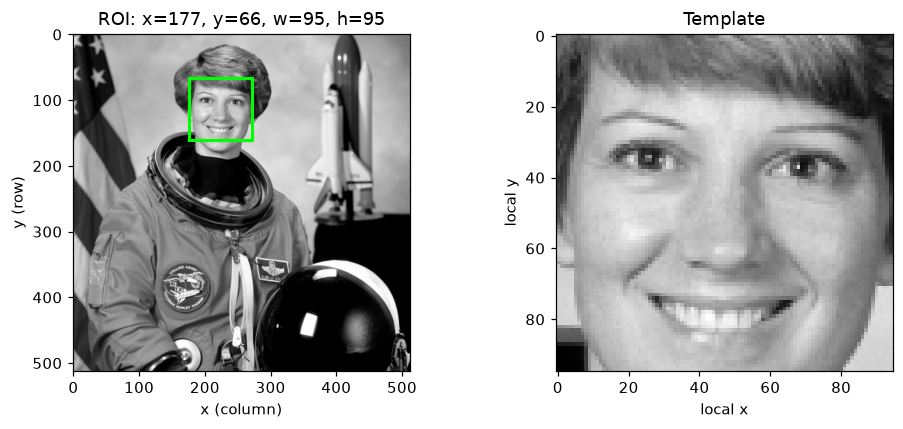

In [4]:
x, y, w, h = 177, 66, 95, 95  # 직접 찍은 사진이면 이 좌표를 수정
H, W = gray.shape
assert 0 <= x and 0 <= y and x+w <= W and y+h <= H, 'ROI가 사진 밖입니다.'
templ = gray[y:y+h, x:x+w].copy()
assert templ.shape == (h, w) and templ.std() > 0, '유효한 비상수 템플릿을 선택하세요.'
print('STEP2:', templ.shape, '| mean:', round(templ.mean(), 2), '| std:', round(templ.std(), 2))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].imshow(gray, cmap='gray', vmin=0, vmax=255)
axes[0].add_patch(plt.Rectangle((x-.5, y-.5), w, h, fill=False, ec='lime', lw=2))
axes[0].set_title(f'ROI: x={x}, y={y}, w={w}, h={h}')
axes[0].set(xlabel='x (column)', ylabel='y (row)')
axes[1].imshow(templ, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Template')
axes[1].set(xlabel='local x', ylabel='local y')
plt.tight_layout()
plt.show()


## STEP 3. 모든 위치의 점수 계산

템플릿의 왼쪽 위를 검색 영상의 $(u,v)$에 놓았을 때 겹치는 패치를 $P_{u,v}$라 하겠습니다. `TM_CCOEFF_NORMED`는 평균을 뺀 뒤 정규화한 상관계수를 계산합니다.

$$R(u,v)=\frac{\sum_{j=0}^{h-1}\sum_{i=0}^{w-1}(T_{ji}-\bar T)(I_{v+j,u+i}-\bar P_{u,v})}{\sqrt{\sum_{j,i}(T_{ji}-\bar T)^2}\sqrt{\sum_{j,i}(I_{v+j,u+i}-\bar P_{u,v})^2}}$$

$\bar T$와 $\bar P_{u,v}$는 각각 템플릿과 **현재 패치**의 평균입니다. 영상 전체 평균을 빼는 것이 아닙니다. 두 패턴의 밝고 어두운 변화가 함께 움직이는지를 비교합니다.

- 분모가 0이 아닌 이상적인 경우 점수 범위는 $[-1,1]$입니다. 실제 계산에서는 부동소수점 오차가 있습니다.
- 1에 가까우면 밝기 변화 패턴이 비슷하고, 0 부근이면 선형 상관이 약하고, -1에 가까우면 밝고 어두운 패턴이 반대입니다.
- **점수 0.9는 ‘얼굴일 확률 90%’가 아닙니다.** 확률로 보정한 값이 아닙니다.
- 비상수 템플릿이라도 검색 패치의 분산이 0인 위치에서는 수학적 식이 정의되지 않습니다. 라이브러리의 예외 처리 점수를 의미 있는 상관으로 해석하지 않습니다.

템플릿 전체가 사진 안에 들어가는 위치만 계산하므로 다음 크기가 됩니다.

$$R.\mathrm{shape}=(H-h+1,\;W-w+1)$$

512×512 영상에 95×95 템플릿이면 418×418개의 점수가 생깁니다. 마지막 가능한 왼쪽 위 좌표가 `(417, 417)`이기 때문에 `+1`이 필요합니다. 이 방법은 최고점이 좋은 매칭인 방식이며, 차이의 제곱합을 쓰는 `TM_SQDIFF` 계열은 최저점을 찾아야 하므로 혼동하지 마세요.


In [5]:
res = cv2.matchTemplate(gray, templ, cv2.TM_CCOEFF_NORMED)
print('STEP3:', res.shape, '| min:', float(res.min()), '| max:', float(res.max()))
print('예상 점수 지도 크기:', (H-h+1, W-w+1))
assert res.shape == (H-h+1, W-w+1)


STEP3: (418, 418) | min: -0.5609174966812134 | max: 0.999999463558197
예상 점수 지도 크기: (418, 418)


### 수식과 라이브러리 결과를 한 위치에서 직접 비교

아래 코드는 설명용으로 한 패치의 상관계수를 직접 계산합니다. 큰 영상의 모든 위치를 Python 반복문으로 계산하면 느리므로 실제 전체 검색에는 OpenCV를 사용합니다. 정수 연산의 범위 문제를 피하기 위해 평균을 빼기 전에 `float64`로 바꿉니다.


In [6]:
def ncc_at(image, template, u, v):
    th, tw = template.shape
    a = template.astype(np.float64)
    b = image[v:v+th, u:u+tw].astype(np.float64)
    assert a.shape == b.shape
    a = a - a.mean()
    b = b - b.mean()
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    return float(np.sum(a*b)/denom) if denom > 0 else float('nan')

for u, v in [(x, y), (0, 0), (min(x+12, W-w), y)]:
    print(f'(x={u}, y={v}): direct={ncc_at(gray, templ, u, v):.6f}, OpenCV={res[v,u]:.6f}')
assert np.isclose(ncc_at(gray, templ, x, y), res[y,x], atol=1e-5)


(x=177, y=66): direct=1.000000, OpenCV=0.999999
(x=0, y=0): direct=-0.281701, OpenCV=-0.281701
(x=189, y=66): direct=0.486839, OpenCV=0.486838


## STEP 4. 최고 점수와 위치 찾기

`cv2.minMaxLoc()`는 `(최솟값, 최댓값, 최솟값 위치, 최댓값 위치)`를 반환합니다. 위치는 **(x, y)** 순서입니다. 반대로 배열에서 같은 점수를 읽을 때는 `res[y, x]`입니다.

현재는 검색 영상에서 잘라낸 템플릿을 같은 영상에 다시 검색합니다. 그러므로 원래 위치에서 거의 1의 점수가 나오는 것이 자연스럽습니다. 이것은 코드와 좌표를 확인하는 **자기 매칭 확인**이며, 새로운 사진에서의 인식 성능 검증은 아닙니다. 똑같은 패턴이 여러 곳 있으면 최고점 위치가 하나만의 정답이 아닐 수도 있습니다.


In [7]:
min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)
print('STEP4 최고 점수:', max_val, '| 위치 (x,y):', max_loc)
print('원본 ROI 위치:', (x,y), '| 해당 점수 res[y,x]:', float(res[y,x]))
print('최고점의 배열 접근:', float(res[max_loc[1], max_loc[0]]))


STEP4 최고 점수: 0.999999463558197 | 위치 (x,y): (177, 66)
원본 ROI 위치: (177, 66) | 해당 점수 res[y,x]: 0.999999463558197
최고점의 배열 접근: 0.999999463558197


## STEP 5. 점수 지도와 가로 단면 읽기

점수 지도의 한 픽셀은 검색 영상의 **템플릿 왼쪽 위 위치**를 나타냅니다. 얼굴의 중심 위치를 나타내는 것은 아닙니다. 중심은 최고점에 `(w/2, h/2)`를 더해서 구합니다.

첫 그림은 범위를 -1~1로 고정한 실제 점수 지도입니다. 두 번째는 원본처럼 최솟값~최댓값을 0~255로 늘린 컬러 지도입니다. 이 재조정은 보기에 편하지만, 서로 다른 사진의 지도를 같은 색만 보고 비교할 수 없게 만듭니다. 절대 점수와 컬러바를 함께 확인하세요.

가로 단면은 정답의 y행에서 x를 바꿨을 때 점수가 어떻게 변하는지 보여 줍니다. 주변 위치의 겹치는 패치들은 서로 비슷하므로 독립적인 관측이 아니며, 최고점 주변에도 높은 값이 나타날 수 있습니다.


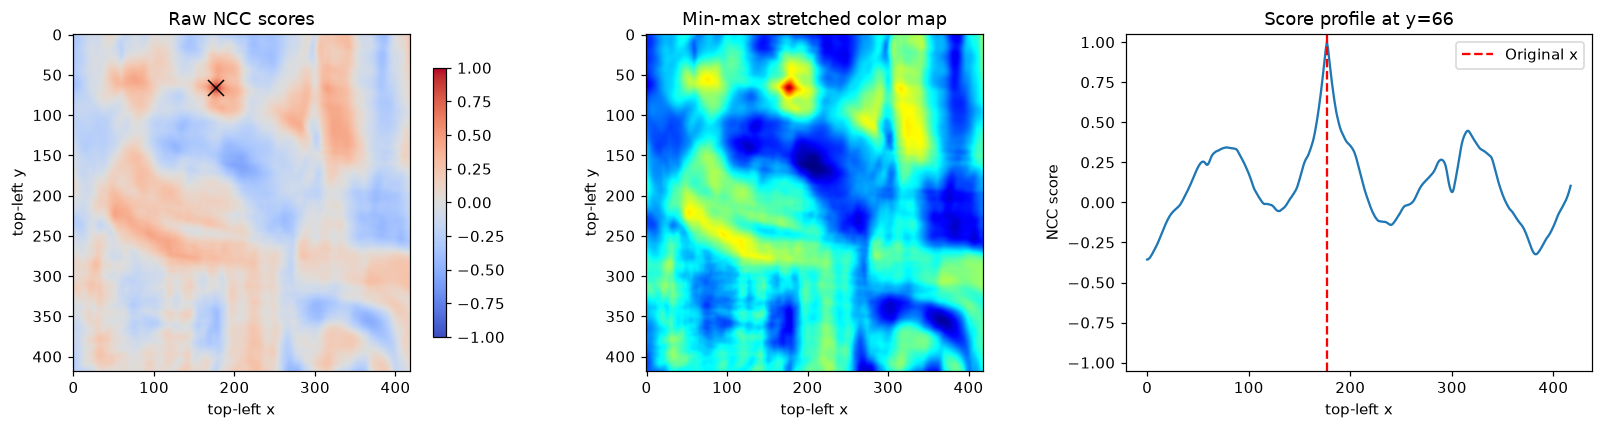

In [8]:
heat = cv2.normalize(res, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
heat_bgr = cv2.applyColorMap(heat, cv2.COLORMAP_JET)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
im = axes[0].imshow(res, cmap='coolwarm', vmin=-1, vmax=1)
axes[0].plot(*max_loc, 'kx', ms=10)
axes[0].set(title='Raw NCC scores', xlabel='top-left x', ylabel='top-left y')
fig.colorbar(im, ax=axes[0], shrink=0.8)
axes[1].imshow(cv2.cvtColor(heat_bgr, cv2.COLOR_BGR2RGB))
axes[1].set(title='Min-max stretched color map', xlabel='top-left x', ylabel='top-left y')
axes[2].plot(np.arange(res.shape[1]), res[y,:])
axes[2].axvline(x, color='r', ls='--', label='Original x')
axes[2].set(title=f'Score profile at y={y}', xlabel='top-left x', ylabel='NCC score', ylim=(-1.05,1.05))
axes[2].legend()
plt.tight_layout()
plt.show()


## STEP 6. 찾은 위치에 상자 그리기

최고점은 템플릿 왼쪽 위입니다. 오른쪽 아래는 `(x+w, y+h)`로 표현할 수 있습니다. 이 노트북의 계산용 상자는 `[x, x+w) × [y, y+h)`의 반열린 구간으로 통일합니다. 픽셀 인덱스의 양 끝을 포함해 그리는 OpenCV 사각형에는 `(x+w-1, y+h-1)`을 사용합니다.

시각화 전에 `img.copy()`를 만드는 이유는 원본 영상에 선을 그려 다음 검색의 입력을 바꾸지 않기 위해서입니다.


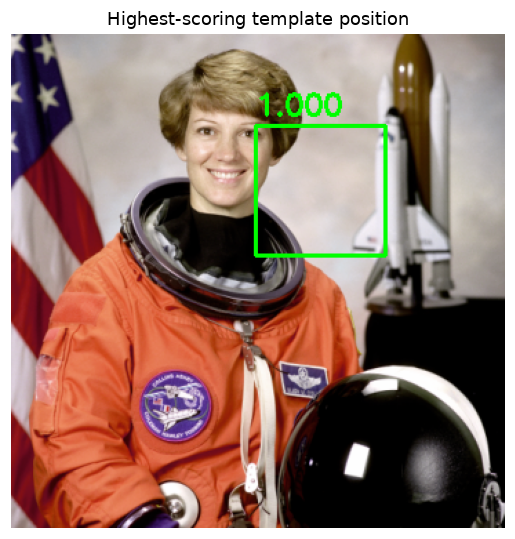

In [ ]:
vis = img.copy()
# new_width = int(img.shape[1] *0.7)
# new_height = int(img.shape[0] *0.7)
# new_size = (new_width, new_height)

# vis = cv2.resize(vis, new_size, interpolation=cv2.INTER_AREA)
px, py = max_loc
cv2.rectangle(vis, (px,py), (px+w-1,py+h-1), (0,255,0), 2)
cv2.putText(vis, f'{max_val:.3f}', (px,max(20,py-8)), cv2.FONT_HERSHEY_SIMPLEX, .7, (0,255,0), 2)
plt.figure(figsize=(6,5))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title('Highest-scoring template position')
plt.axis('off')
plt.tight_layout()
plt.show()


## STEP 7. 템플릿을 고정하고 검색 사진만 바꾸기

원본과 같이 0.6배 축소, 0.5배 어둡게 하기, 좌우 반전을 비교합니다. 검색 영상만 바꾸고 원래 95×95 템플릿은 그대로 둡니다.

**밝기:** 패치가 $P'=aP+b$이고 $a>0$이며 반올림·클리핑이 없다면, 평균 제거가 $b$를 없애고 정규화가 $a$를 상쇄합니다. 따라서 이 상관계수는 양의 선형 밝기 변화에 강합니다. 실제 `uint8` 변환의 반올림이나 밝기 포화, 그림자·비선형 변화에서는 완전히 같지 않을 수 있습니다. 평균을 빼지 않는 다른 매칭 방법에는 동일한 설명을 그대로 적용할 수 없습니다.

**크기:** 축소된 얼굴과 원래 크기의 템플릿은 윤곽 위치가 다릅니다. 위치만 바꾸는 검색으로 크기 차이를 보정하지 못합니다.

**좌우 반전:** 얼굴·머리카락·주변 배경의 좌우 패턴이 달라집니다. 얼굴이 어느 정도 대칭이더라도 동일한 픽셀 패턴은 아닙니다.

축소 영상의 정답 상자는 실제 출력 너비·높이의 비율로 변환합니다. 반전의 정답 왼쪽 위 x는 `W-(x+w)`입니다. 축소 후의 정답 크기는 약 57×57이지만 단일 크기 검색 상자는 여전히 95×95라는 점에 주목하세요.


In [22]:
small = cv2.resize(gray, None, fx=0.6, fy=0.6)
sx, sy = small.shape[1]/W, small.shape[0]/H
tests = {
    'Original': (gray, (x,y,w,h)),
    'Small x0.6': (small, (x*sx,y*sy,w*sx,h*sy)),
    'Dark x0.5': (cv2.convertScaleAbs(gray, alpha=.5, beta=0), (x,y,w,h)),
    'Horizontal flip': (cv2.flip(gray,1), (W-x-w,y,w,h))
}

def box_iou(a,b):
    ax,ay,aw,ah=a; bx,by,bw,bh=b
    inter=max(0,min(ax+aw,bx+bw)-max(ax,bx))*max(0,min(ay+ah,by+bh)-max(ay,by))
    return inter/(aw*ah+bw*bh-inter)

results = []
print('case                 score        location      center error(px)    ROI IoU')
for name,(g,gt) in tests.items():
    assert g.shape[0]>=h and g.shape[1]>=w
    r=cv2.matchTemplate(g,templ,cv2.TM_CCOEFF_NORMED)
    _,v,_,loc=cv2.minMaxLoc(r)
    box=(*loc,w,h)
    center_error=np.linalg.norm(np.array([loc[0]+w/2,loc[1]+h/2])-np.array([gt[0]+gt[2]/2,gt[1]+gt[3]/2]))
    iou=box_iou(box,gt)
    results.append(dict(name=name,image=g,score=v,loc=loc,gt=gt,iou=iou,center_error=center_error))
    print(f'{name:<20} {v:7.4f}   {str(loc):>13}    {center_error:10.2f}        {iou:.3f}')


case                 score        location      center error(px)    ROI IoU
Original              1.0000       (177, 66)          0.00        1.000
Small x0.6            0.5806       (164, 36)         78.42        0.000
Dark x0.5             0.9999       (177, 66)          0.00        1.000
Horizontal flip       0.5303       (143, 91)        100.17        0.000


### 왜 점수와 위치 오차를 함께 볼까요?

템플릿 매칭은 대상이 없어도 검색 가능한 위치 중 **최고점 하나를 항상 반환**합니다. 그래서 최고 점수가 나왔다는 사실만으로 검출 성공을 선언할 수 없습니다.

아래에서는 원래 ROI를 변환한 영역을 기준으로 위치를 확인합니다. 녹색은 예측, 주황색 점선은 변환된 정답 ROI입니다. 정답은 사람이 새로 표기한 얼굴 경계가 아니라 **처음 선택한 사각형이 변환된 영역**입니다.

$$\mathrm{IoU}(A,B)=\frac{|A\cap B|}{|A\cup B|}$$

IoU는 두 상자의 겹침 정도이고, 중심 오차는 중심점 사이의 유클리드 거리입니다. 올바른 얼굴 중심 근처를 찾았더라도 상자 크기가 잘못되면 IoU는 작아질 수 있습니다. 픽셀 단위 중심 오차는 영상 해상도에도 영향을 받습니다.


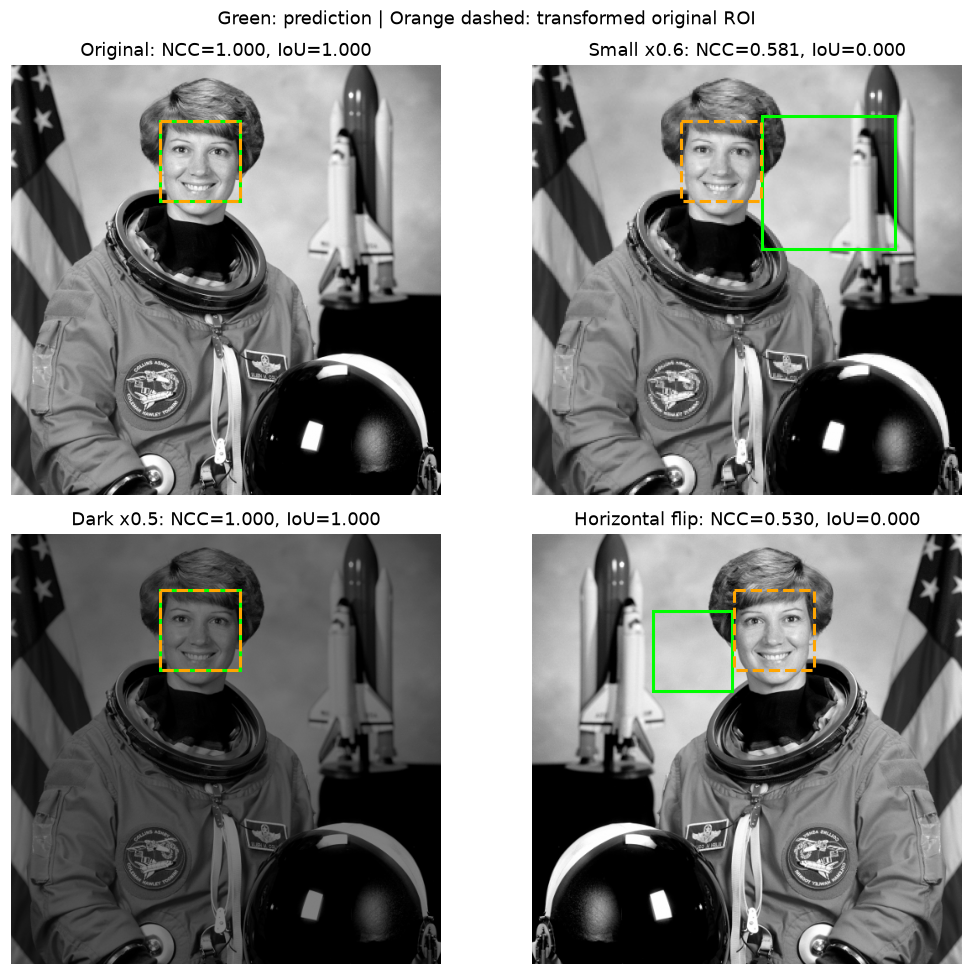

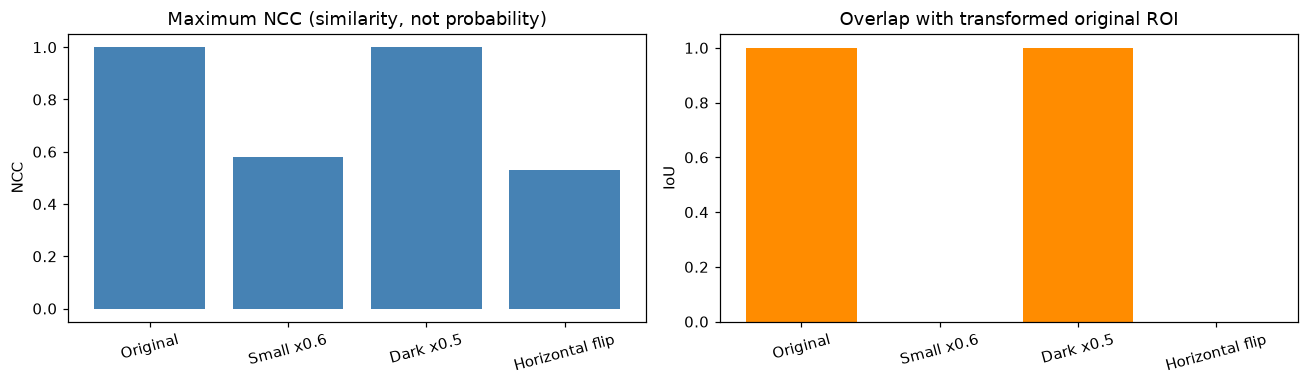

In [23]:
fig,axes=plt.subplots(2,2,figsize=(10,9))
for ax,r in zip(axes.flat,results):
    ax.imshow(r['image'],cmap='gray',vmin=0,vmax=255)
    ax.add_patch(plt.Rectangle(r['loc'],w,h,fill=False,ec='lime',lw=2))
    gx,gy,gw,gh=r['gt']
    ax.add_patch(plt.Rectangle((gx,gy),gw,gh,fill=False,ec='orange',lw=2,ls='--'))
    ax.set_title(f"{r['name']}: NCC={r['score']:.3f}, IoU={r['iou']:.3f}")
    ax.axis('off')
fig.suptitle('Green: prediction | Orange dashed: transformed original ROI')
plt.tight_layout()
plt.show()

fig,axes=plt.subplots(1,2,figsize=(12,3.6))
names=[r['name'] for r in results]
axes[0].bar(names,[r['score'] for r in results],color='steelblue')
axes[0].set(title='Maximum NCC (similarity, not probability)',ylabel='NCC',ylim=(-.05,1.05))
axes[1].bar(names,[r['iou'] for r in results],color='darkorange')
axes[1].set(title='Overlap with transformed original ROI',ylabel='IoU',ylim=(0,1.05))
for ax in axes:
    ax.tick_params(axis='x',rotation=15)
plt.tight_layout()
plt.show()


## 추가 실험. 밝기 배율에 따른 점수 곡선

밝기 배율을 0.25~1.75로 바꾸며 전체 영상의 최고 점수와 **알고 있는 정답 위치의 점수**를 각각 기록합니다. 최고점이 다른 곳으로 옮겨 가면 두 값은 달라질 수 있습니다.

1보다 큰 배율에서는 밝은 픽셀이 255로 포화될 수 있습니다. `convertScaleAbs`는 변환값의 절댓값과 8비트 변환을 적용하므로, 음수 배율까지 일반적인 선형 밝기 모델로 해석하지 않습니다. 여기서는 양의 배율만 사용합니다.


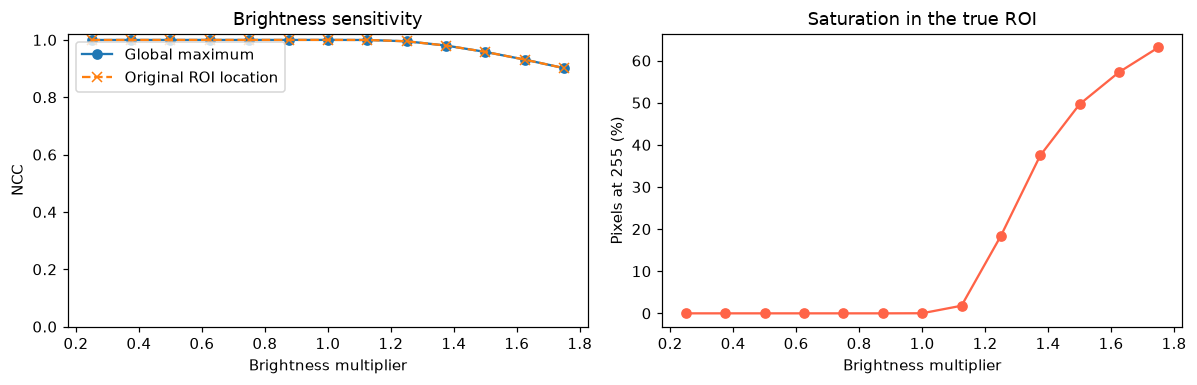

In [12]:
alphas=np.linspace(.25,1.75,13)
peak_scores=[]; known_scores=[]; saturated=[]
for a in alphas:
    g=cv2.convertScaleAbs(gray,alpha=float(a),beta=0)
    r=cv2.matchTemplate(g,templ,cv2.TM_CCOEFF_NORMED)
    peak_scores.append(float(r.max()))
    known_scores.append(float(r[y,x]))
    saturated.append(float((g[y:y+h,x:x+w]==255).mean()))
fig,axes=plt.subplots(1,2,figsize=(11,3.6))
axes[0].plot(alphas,peak_scores,'o-',label='Global maximum')
axes[0].plot(alphas,known_scores,'x--',label='Original ROI location')
axes[0].set(xlabel='Brightness multiplier',ylabel='NCC',title='Brightness sensitivity',ylim=(0,1.02))
axes[0].legend()
axes[1].plot(alphas,np.array(saturated)*100,'o-',color='tomato')
axes[1].set(xlabel='Brightness multiplier',ylabel='Pixels at 255 (%)',title='Saturation in the true ROI')
plt.tight_layout()
plt.show()


## 실습 과제와 해설

1. **418×418은 왜 나올까요?** 마지막 왼쪽 위 좌표가 417이므로 0~417까지 418개 위치입니다.
2. **`res[66,177]`과 `(177,66)`은 같은 위치인가요?** 그렇습니다. 배열은 `[y,x]`, OpenCV 위치는 `(x,y)`입니다.
3. **어두워도 점수가 높은 이유는?** 정규화 상관계수가 양의 선형 밝기 변화에 이론적으로 불변이기 때문입니다. 반올림·포화·비선형 조명 변화까지 해결하는 것은 아닙니다.
4. **축소하면 왜 약해지나요?** 템플릿의 크기는 고정되어 있고 위치만 탐색하기 때문입니다. 다음 다중 스케일 실습에서 템플릿 크기도 탐색합니다.
5. **점수 0.8이면 얼굴이라고 확신해도 되나요?** 아닙니다. 대상이 없는 사진도 최고점을 반환합니다. 임계 점수를 정하려면 대상이 있는 사진과 없는 사진을 따로 모아 검증해야 합니다.
6. **다른 사람의 얼굴도 찾나요?** 이 방법은 지정한 픽셀 패턴을 검색합니다. 다른 사람·다른 표정·다른 자세에서 일반적인 얼굴 검출을 보장하지 않습니다.

**직접 해 볼 일**

- 템플릿을 얼굴 전체·눈 주변·배경 일부로 바꾸어 최고점과 점수 지도 모양을 비교하세요.
- 점수 지도의 min-max 재조정 그림과 고정 범위 그림을 비교하세요. 색이 비슷해도 실제 최고 점수가 같은지 확인하세요.
- 차이의 제곱합 방식으로 바꿔 보세요. 점수의 의미와 최적점 방향도 함께 수정해야 합니다.
- 대상이 없는 다른 사진에서 최고점을 구하고, 그 위치가 왜 ‘검출 성공’이 아닌지 설명하세요.

| 실험 조건 | 템플릿 크기 | 최고 점수 | 최고점 위치 | ROI IoU | 관찰 |
|---|---|---|---|---|---|
| 원본 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 |
| 축소 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 |
| 밝기 변경 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 | 직접 기록 |

**실행 점검:** 아래 검사는 배열 크기와 기본 수치의 일관성을 확인합니다. 모든 변화에서 정확히 검출된다는 보장은 아닙니다.


In [13]:
assert res.shape==(gray.shape[0]-h+1,gray.shape[1]-w+1)
assert np.isfinite(res).all()
assert max_val>.99
assert len(results)==4
assert all(0<=r['iou']<=1 for r in results)
print('배열 크기·자기 매칭·IoU 범위 확인 완료')


배열 크기·자기 매칭·IoU 범위 확인 완료
